In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Load dataset

df = pd.read_csv("C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv")

# Create binary target

df_model = df.copy()

df_model["target"] = (df_model["num"] > 0).astype(int)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df_model["target"].value_counts())

Dataset loaded successfully.
Dataset shape: (900, 77)

Target distribution:
target
1    496
0    404
Name: count, dtype: int64


In [4]:
# Select clinically relevant features

selected_features = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
]

X = df_model[selected_features].copy()
y = df_model["target"].copy()

# Handle remaining missing values

for column in X.columns:
    if X[column].isnull().sum() > 0:
        X[column] = X[column].fillna(X[column].median())

print("Selected features:", len(selected_features))
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

print("\nRemaining missing values:", X.isnull().sum().sum())

Selected features: 13
Feature matrix: (900, 13)
Target vector: (900,)

Remaining missing values: 0


In [5]:
# Stratified 80:20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (720, 13)
Testing data : (180, 13)

Training class distribution:
target
1    397
0    323
Name: count, dtype: int64

Testing class distribution:
target
1    99
0    81
Name: count, dtype: int64


In [6]:
# Create Decision Tree model

decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

print("Decision Tree configuration")
print("===========================")

print("Criterion:", decision_tree.criterion)
print("Maximum depth:", decision_tree.max_depth)
print("Minimum samples split:", decision_tree.min_samples_split)
print("Minimum samples leaf:", decision_tree.min_samples_leaf)

Decision Tree configuration
Criterion: gini
Maximum depth: 5
Minimum samples split: 10
Minimum samples leaf: 4


In [7]:
# Train Decision Tree

decision_tree.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [8]:
# Generate predictions

y_pred = decision_tree.predict(X_test)

# Generate probability predictions

y_prob = decision_tree.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(np.round(y_prob[:10], 4))

Predictions generated successfully.

First 10 predicted classes:
[0 0 1 1 0 1 0 1 1 1]

First 10 predicted probabilities:
[0.3889 0.0795 0.6452 0.8333 0.     0.96   0.3889 0.641  0.6471 0.8333]


In [9]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

decision_tree_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(decision_tree_results.round(4))

,Metric,Score
0,Accuracy,0.7889
1,Precision,0.7850
2,Recall,0.8485
3,F1 Score,0.8155
4,ROC-AUC,0.8509


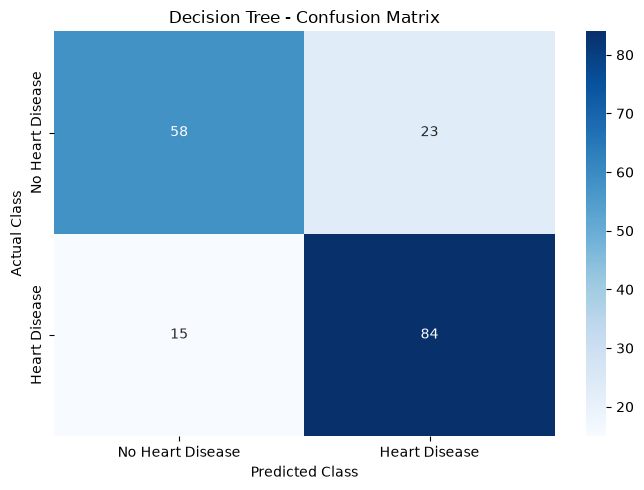


Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.79      0.72      0.75        81
   Heart Disease       0.79      0.85      0.82        99

        accuracy                           0.79       180
       macro avg       0.79      0.78      0.78       180
    weighted avg       0.79      0.79      0.79       180



In [10]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Heart Disease",
        "Heart Disease"
    ],
    yticklabels=[
        "No Heart Disease",
        "Heart Disease"
    ]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# Classification Report

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)

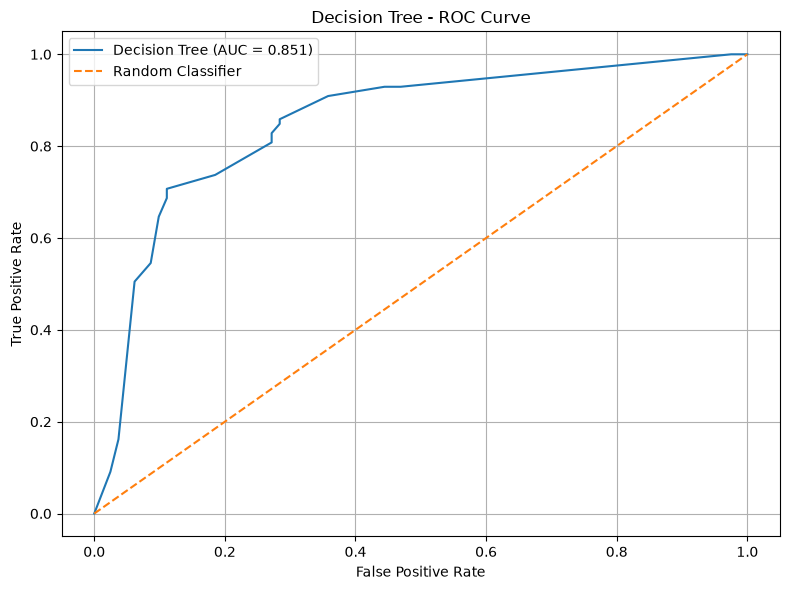

In [11]:
# Generate ROC curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Decision Tree - ROC Curve")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [12]:
# Perform 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Decision Tree 5-Fold Cross-Validation")
print("======================================")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Decision Tree 5-Fold Cross-Validation
Fold 1: 0.8056
Fold 2: 0.7431
Fold 3: 0.7986
Fold 4: 0.7292
Fold 5: 0.7569

Mean CV Accuracy: 0.7667
Standard Deviation: 0.0303


Feature Importance:


,Feature,Importance
2,cp,0.4773
0,age,0.0942
4,chol,0.0803
9,oldpeak,0.0630
12,thal,0.0600
1,sex,0.0564
7,thalach,0.0532
8,exang,0.0519
3,trestbps,0.0337
5,fbs,0.0234


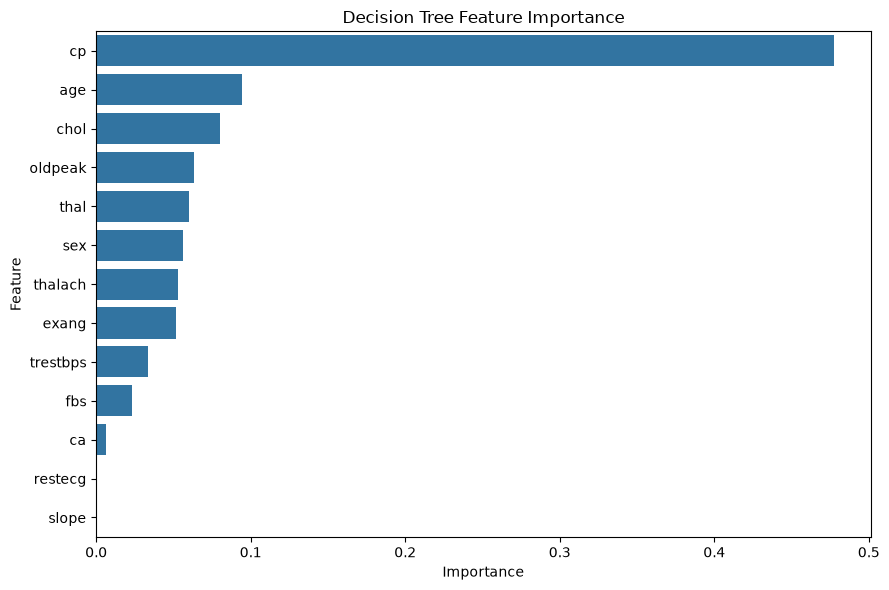

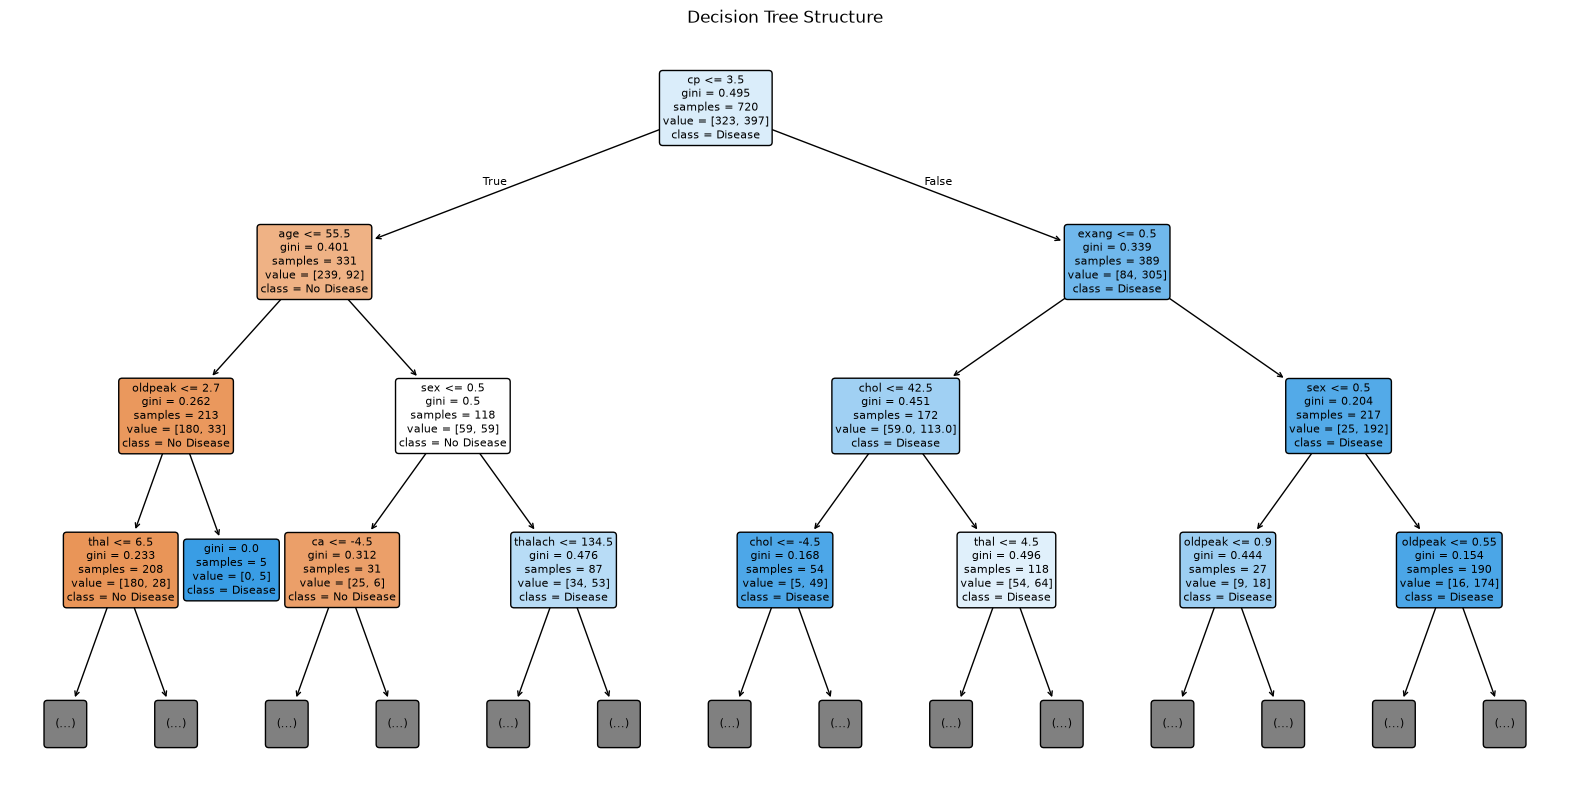

In [13]:
# Feature importance

importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": decision_tree.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(importance.round(4))


# Plot feature importance

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# Display decision tree

plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree,
    feature_names=selected_features,
    class_names=[
        "No Disease",
        "Disease"
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Structure")
plt.show()

In [14]:
# Error analysis

prediction_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability": y_prob
})

prediction_analysis["Correct"] = (
    prediction_analysis["Actual"] ==
    prediction_analysis["Predicted"]
)

incorrect = prediction_analysis[
    prediction_analysis["Correct"] == False
]

print("DECISION TREE FINAL RESULTS")
print("===========================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nCross-Validation:")
print(f"Mean Accuracy : {cv_scores.mean():.4f}")
print(f"Std Deviation : {cv_scores.std():.4f}")

print("\nPrediction Analysis:")
print("Total test observations:", len(prediction_analysis))
print("Correct predictions:", prediction_analysis["Correct"].sum())
print("Incorrect predictions:", len(incorrect))

DECISION TREE FINAL RESULTS
Accuracy  : 0.7889
Precision : 0.7850
Recall    : 0.8485
F1 Score  : 0.8155
ROC-AUC   : 0.8509

Cross-Validation:
Mean Accuracy : 0.7667
Std Deviation : 0.0303

Prediction Analysis:
Total test observations: 180
Correct predictions: 142
Incorrect predictions: 38
